In [30]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(torch.__version__)

2.14.1


In [31]:
import sys

print(sys.executable)
print(sys.version)

/usr/local/bin/python3
3.13.1 (v3.13.1:06714517797, Dec  3 2024, 14:00:22) [Clang 15.0.0 (clang-1500.3.9.4)]


In [32]:
%pip install torch



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [33]:
x = torch.tensor(3.0, requires_grad= True)

loss = (x - 5) ** 2
#calculates derivatives with respect to all tracked input tensors that contributed to the loss, rather than one variable chosen by its name. what it does is, it takes function (x - 5) ** 2, and says it is just u^2, then it takes derivative of L w.r.t u, then u w.r.t x, and chain rule tells, multiplication of these two will be derivative of L w.r.t. x. 
loss.backward()

print("x:", x)
print("loss:", loss)

#Pytorch automatically, stores del L / del x in x.grad. Once we perform loss.backward, then it calculates derivative of loss, w.r.t to its variable, then puts it in x.grad. well, if the variable was a, you could write everything with y then. 

print("First derivative:", x.grad)

x: tensor(3., requires_grad=True)
loss: tensor(4., grad_fn=<PowBackward0>)
First derivative: tensor(-4.)


In [34]:
a = torch.tensor(3.0, requires_grad= True)

loss = (a - 5) ** 2
#calculates derivatives with respect to all tracked input tensors that contributed to the loss, rather than one variable chosen by its name. what it does is, it takes function (x - 5) ** 2, and says it is just u^2, then it takes derivative of L w.r.t u, then u w.r.t x, and chain rule tells, multiplication of these two will be derivative of L w.r.t. x. 
loss.backward()

print("x:", a)
print("loss:", loss)

#Pytorch automatically, stores del L / del x in x.grad. Once we perform loss.backward, then it calculates derivative of loss, w.r.t to its variable, then puts it in x.grad. well, if the variable was y, you could write everything with y then. 

print("First derivative:", a.grad)

x: tensor(3., requires_grad=True)
loss: tensor(4., grad_fn=<PowBackward0>)
First derivative: tensor(-4.)


In [35]:
x = torch.tensor([1.0,2.0,3.0], requires_grad= True)

L = torch.sum(x ** 2) # this command exactly does this, and finds the norm of the vector squared. x[0]**2 + x[1]**2 + x[2]**2
L.backward()

print(x.grad)

tensor([2., 4., 6.])


In [36]:
X = torch.tensor([[1.0, 2.0], 
                 [3.0, 4.0]])
W = torch.tensor([[1.0, 0.0],
                 [0.0, 1.0]], requires_grad= True)

Z = X @ W
loss = torch.sum(Z ** 2)
loss.backward()

print(W.grad)


tensor([[20., 28.],
        [28., 40.]])


In [37]:
#implemention attention using pytorch


token_ids = torch.tensor([0, 1, 1, 2, 3], dtype = torch.long)

#creating our embedding matrix
E = torch.tensor([[1.0,0.0,1.0,0.0],
                  [0.0,1.0,0.0,1.0],
                  [1.0,1.0,0.0,0.0],
                  [0.0,0.0,1.0,1.0]],requires_grad= True)

#create our query, key, and values matrices

W_Q = torch.tensor([[1.0,0.0],
                   [0.0,1.0],
                   [1.0,0.0],
                   [0.0,1.0]], requires_grad= True)

W_K = torch.tensor([[1.0,0.0],
                   [0.0,1.0],
                   [0.0,1.0],
                   [1.0,0.0]], requires_grad= True)

W_V = torch.tensor([[1.0,0.0,0.0],
                    [0.0,1.0,0.0],
                    [0.0,0.0,1.0],
                    [1.0,1.0,0.0]], requires_grad= True)

#Calculate actual query, key and values matrices using attention recepie

X = E[token_ids]

Q = X @ W_Q
K = X @ W_K
V = X @ W_V




print(X)
print(X.shape)
print(Q.shape)
print(K.shape)
print(V.shape)




tensor([[1., 0., 1., 0.],
        [0., 1., 0., 1.],
        [0., 1., 0., 1.],
        [1., 1., 0., 0.],
        [0., 0., 1., 1.]], grad_fn=<IndexBackward0>)
torch.Size([5, 4])
torch.Size([5, 2])
torch.Size([5, 2])
torch.Size([5, 3])


In [38]:

d_k = Q.shape[1] #number of columns for Q 

S = (Q @ K.T)/(d_k ** 0.5)

print(S)

tensor([[1.4142, 1.4142, 1.4142, 1.4142, 1.4142],
        [1.4142, 1.4142, 1.4142, 1.4142, 1.4142],
        [1.4142, 1.4142, 1.4142, 1.4142, 1.4142],
        [1.4142, 1.4142, 1.4142, 1.4142, 1.4142],
        [1.4142, 1.4142, 1.4142, 1.4142, 1.4142]], grad_fn=<DivBackward0>)


In [39]:
# Causal masking prevents each position from attending to future tokens, avoiding information leakage during next-token prediction.

M = torch.full([X.shape[0],X.shape[0]], float("-inf"))#creates a matrix full of -infinity value with dimension X.shape[0] x X.shape[0]
M = torch.triu(M,diagonal = 1) #diagonal = 1 means strictly above the main diagonal, the diagonal and everything below will receive 0. 

print(M)

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])


In [40]:
S_masked = S + M

print(S_masked)

tensor([[1.4142,   -inf,   -inf,   -inf,   -inf],
        [1.4142, 1.4142,   -inf,   -inf,   -inf],
        [1.4142, 1.4142, 1.4142,   -inf,   -inf],
        [1.4142, 1.4142, 1.4142, 1.4142,   -inf],
        [1.4142, 1.4142, 1.4142, 1.4142, 1.4142]], grad_fn=<AddBackward0>)


In [41]:
#softmax calculation to convert everything to Gibbs probabiulity measure
A = torch.softmax(S_masked, dim = 1)

print(A)
print(A.sum(dim = 1))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]], grad_fn=<SoftmaxBackward0>)
tensor([1., 1., 1., 1., 1.], grad_fn=<SumBackward1>)


In [42]:
#output calculation

O = A @ V

print(A.shape)
print(V.shape)
print(O.shape)

torch.Size([5, 5])
torch.Size([5, 3])
torch.Size([5, 3])


In [43]:
W_vocab = torch.tensor([[1.0,0.0,-1.0,0.0],
                         [0.0,1.0,1.0,-1.0],
                         [-1.0,0.0,0.0,1.0]], requires_grad= True)


target_ids = torch.tensor([1,1,2,3], dtype= torch.long)

O_train = O[:4]

#calculating logits

Z = O_train @ W_vocab



In [44]:
import torch.nn.functional as F

loss = F.cross_entropy(Z, target_ids)
print(loss)



tensor(1.7696, grad_fn=<NllLossBackward0>)


In [45]:
loss.backward()

print(E.grad)
print(W_Q.grad)
print(W_K.grad)
print(W_V.grad)
print(W_vocab.grad)

tensor([[ 0.0114, -0.3266, -0.0534, -0.2942],
        [ 0.3408,  0.1064, -0.1870,  0.4222],
        [ 0.0031,  0.0964, -0.0816,  0.1036],
        [ 0.0000,  0.0000,  0.0000,  0.0000]])
tensor([[-1.3039e-08, -1.3039e-08],
        [-1.8626e-08, -1.8626e-08],
        [ 0.0000e+00,  0.0000e+00],
        [-5.5879e-09, -5.5879e-09]])
tensor([[-0.1340, -0.0250],
        [ 0.1299,  0.0210],
        [-0.1299, -0.0210],
        [ 0.1340,  0.0250]])
tensor([[ 0.1485, -0.2052, -0.1100],
        [ 0.2140,  0.1818, -0.2896],
        [ 0.1413, -0.3056, -0.0325],
        [ 0.2068,  0.0814, -0.2120]])
tensor([[ 0.2559, -0.0905, -0.0994, -0.0661],
        [ 0.2466,  0.1825, -0.1742, -0.2549],
        [ 0.1235, -0.1968, -0.0178,  0.0911]])


In [47]:
#This method of torch is optimizing using gradient descent, with factor 0.1. 
optimizer = torch.optim.SGD(
    [E, W_Q, W_K, W_V, W_vocab], lr  = 0.1 
)


0 1.769589900970459
100 0.6327252388000488
200 0.20708896219730377
300 0.10069804638624191
400 0.03496425226330757
500 0.014992683194577694
600 0.008655178360641003
700 0.005819487385451794
800 0.00427801301702857
900 0.00333156599663198


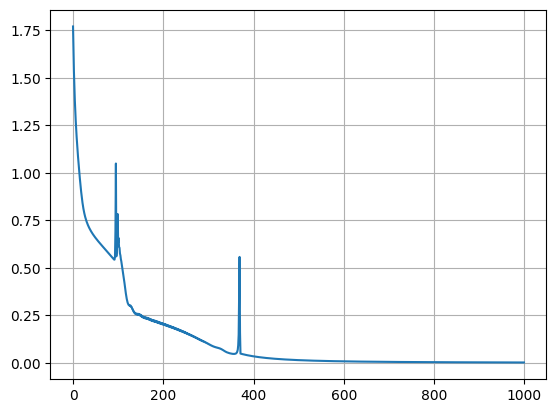

In [53]:
token_ids = torch.tensor([0, 1, 1, 2, 3], dtype = torch.long)
target_ids = torch.tensor([1,1,2,3], dtype= torch.long)


#creating our embedding matrix
E = torch.tensor([[1.0,0.0,1.0,0.0],
                  [0.0,1.0,0.0,1.0],
                  [1.0,1.0,0.0,0.0],
                  [0.0,0.0,1.0,1.0]],requires_grad= True)

X = E[token_ids]

#create our query, key, and values matrices

W_Q = torch.tensor([[1.0,0.0],
                   [0.0,1.0],
                   [1.0,0.0],
                   [0.0,1.0]], requires_grad= True)

W_K = torch.tensor([[1.0,0.0],
                   [0.0,1.0],
                   [0.0,1.0],
                   [1.0,0.0]], requires_grad= True)

W_V = torch.tensor([[1.0,0.0,0.0],
                    [0.0,1.0,0.0],
                    [0.0,0.0,1.0],
                    [1.0,1.0,0.0]], requires_grad= True)

W_vocab = torch.tensor([[1.0,0.0,-1.0,0.0],
                         [0.0,1.0,1.0,-1.0],
                         [-1.0,0.0,0.0,1.0]], requires_grad= True)

M = torch.full([token_ids.shape[0],token_ids.shape[0]], float("-inf")) #creates a matrix full of -infinity value with dimension X.shape[0] x X.shape[0]
M = torch.triu(M,diagonal = 1)

optimizer = torch.optim.SGD(
    [E, W_Q, W_K, W_V, W_vocab ], lr = 0.1
)

loss_history = []
for step in range(1000):
    optimizer.zero_grad()
    X = E[token_ids]

    Q = X @ W_Q
    K = X @ W_K
    V = X @ W_V
#Calculate actual query, key and values matrices using attention recepie

    d_k = Q.shape[1] #number of columns for Q 
    S = (Q @ K.T)/(d_k ** 0.5)
    S_masked = S + M
    A = torch.softmax(S_masked, dim = 1)
    O = A @ V

   
    O_train = O[:len(target_ids)]
    #calculating logits
    Z = O_train @ W_vocab
    loss = F.cross_entropy(Z, target_ids)
    loss_history.append(loss.item())
    loss.backward()
    optimizer.step()

    if step % 100==0:
        print(step, loss.item())

    

plt.plot(loss_history)
plt.grid()
plt.show()

